# 06.3 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/03-choosing-k/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
names = list("ABCDEFGH")
points = np.array([[1, 1], [1, 3], [2, 2], [4, 3], [6, 6], [7, 5], [7, 8], [9, 7]], dtype=float)
labels = np.array([0, 0, 0, 0, 1, 1, 1, 1])            # final clusters from 06.2

## Exercise 1

$a$ = average distance from E to F, G, H = $(\sqrt{2} + \sqrt{5} + \sqrt{10})/3 = (1.414 + 2.236 + 3.162)/3 = 2.271$

$b$ = average distance from E to A, B, C, D = $(\sqrt{50} + \sqrt{34} + \sqrt{32} + \sqrt{13})/4 = (7.071 + 5.831 + 5.657 + 3.606)/4 = 5.541$

$s(E) = (5.541 - 2.271)/5.541 = 0.590$

In [3]:
from sklearn.metrics import silhouette_samples
E = points[4]
dist = np.linalg.norm(points - E, axis=1)
a, b = dist[[5, 6, 7]].mean(), dist[[0, 1, 2, 3]].mean()
print(f"a = {a:.3f}  b = {b:.3f}  s(E) = {(b - a) / max(a, b):.3f}")
print({n: float(v) for n, v in zip(names, silhouette_samples(points, labels).round(3))})

a = 2.271  b = 5.541  s(E) = 0.590
{'A': 0.721, 'B': 0.704, 'C': 0.758, 'D': 0.394, 'E': 0.59, 'F': 0.58, 'G': 0.675, 'H': 0.677}


In [4]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [5]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)                         # tame the long right tails
X = StandardScaler().fit_transform(rfm_log)      # mean 0, std 1 per column
print("X shape:", X.shape)

X shape: (4338, 3)


In [6]:
def profile(labels):
    """Size, mean R/F/M and revenue share per cluster, sorted by mean spend."""
    p = rfm.assign(cluster=labels).groupby("cluster").agg(
        customers=("recency", "size"), recency=("recency", "mean"),
        frequency=("frequency", "mean"), monetary=("monetary", "mean"))
    p["revenue_share"] = rfm.groupby(labels)["monetary"].sum() / rfm["monetary"].sum()
    return p.sort_values("monetary", ascending=False)

## Exercise 2

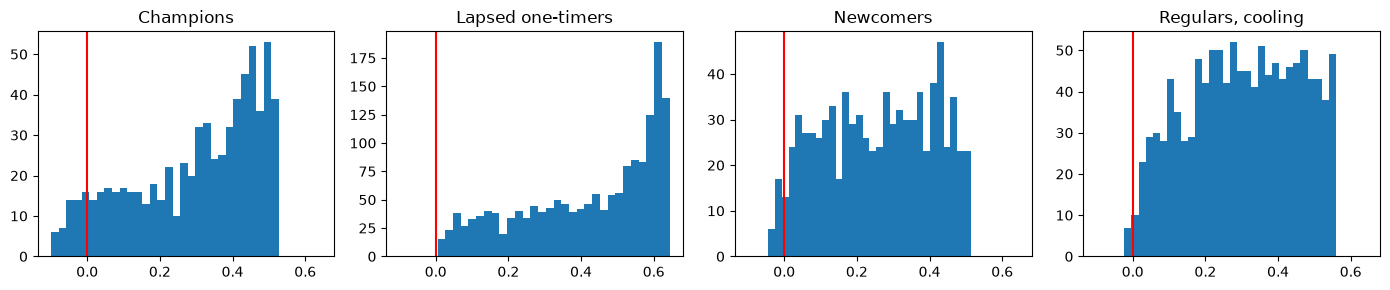

persona
Champions            0.076
Lapsed one-timers    0.000
Newcomers            0.031
Regulars, cooling    0.008
Name: s, dtype: float64


In [7]:
from sklearn.cluster import KMeans
labels4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X)
p4 = profile(labels4)
persona_of = dict(zip(p4.index, ["Champions", "Regulars, cooling", "Newcomers", "Lapsed one-timers"]))
sil = pd.DataFrame({"persona": pd.Series(labels4).map(persona_of), "s": silhouette_samples(X, labels4)})

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True)
for ax, (name, grp) in zip(axes, sil.groupby("persona")):
    ax.hist(grp["s"], bins=30); ax.axvline(0, color="red"); ax.set_title(name)
plt.tight_layout(); plt.show()
print(sil.groupby("persona")["s"].apply(lambda s: (s < 0).mean()).round(3))

**Champions** have the largest share of negative silhouettes (about 8%). They are spread over a wide range, from customers with 5 orders to customers with 200, and their lower edge shades smoothly into the Regulars. The customers with negative values sit on that border: frequent enough to look like champions, but not by much. **Lapsed one-timers** have none: a single order long ago is a very distinctive profile.

## Exercise 3

In [8]:
labels5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X)
agg = rfm.assign(cluster=labels5).groupby("cluster").agg(
    customers=("recency", "size"), R_mean=("recency", "mean"), R_median=("recency", "median"),
    F_mean=("frequency", "mean"), F_median=("frequency", "median"),
    M_mean=("monetary", "mean"), M_median=("monetary", "median"))
agg.sort_values("M_mean", ascending=False).round(1)

,customers,R_mean,R_median,F_mean,F_median,M_mean,M_median
cluster,,,,,,,
2,292,9.2,4.0,22.3,17.0,15231.5,6702.9
3,973,20.9,16.0,6.3,6.0,2431.6,1972.4
4,1043,106.9,81.0,2.9,3.0,1351.9,947.4
1,806,22.8,21.0,1.8,2.0,421.7,366.5
0,1224,201.4,203.0,1.2,1.0,264.5,236.2


The **Champions** split: a small core (about 290 customers, ~22 orders, ~£15,000 on average) separates from a larger "active loyal" group (~970 customers, ~6 orders, ~£2,400). The other groups shuffle: cooling regulars and lapsed customers are re-cut along recency.

Would marketing treat them differently? Probably yes: the core is worth a personal account manager; the active loyal group a loyalty programme. That is an argument for 5. Notice also how far apart the **means and medians** of spend are in the top group: a few very large customers pull the mean up.

## Exercise 4 (example)

> We recommend **four customer segments**. Mathematically, two groups (active vs inactive) separate most cleanly, but four groups score almost as well (silhouette 0.337 vs 0.338 for three) and are stable when we re-run the analysis. More importantly, each of the four calls for a different action: VIP treatment for the 699 Champions who bring in 64% of revenue, a "we miss you" nudge for 1,178 cooling Regulars, a welcome series for 826 Newcomers, and a low-cost reactivation email for 1,635 Lapsed one-timers. A fifth group (a core of about 290 top customers) is worth considering if account management is available.